# Rectified flow: comparison

$$
(Z_0,Z_1)=\left(Z_0,\Phi_\theta(Z_0)\right),\qquad Z_0\sim\mathcal N(0,I).
$$
$$
Z_t=(1-t)Z_0+tZ_1,\qquad
\mathcal L_{\mathrm{reflow}}(\phi)=
\mathbb E\left[\frac{\|v_\phi(Z_T,T)-(Z_1-Z_0)\|^2}{3072}\right].
$$

[Paper](https://arxiv.org/abs/2209.03003) · [U-Net](../model/model.py)

In [1]:
import sys
from functools import partial
from time import perf_counter
import numpy as np
import jax
import jax.numpy as jnp
from datasets import load_dataset

sys.path.insert(0, "..")
from model.model import init_model, model_apply


data = load_dataset("uoft-cs/cifar10")
X_train = np.stack([np.asarray(image) for image in data["train"]["img"]])
X_train = X_train.astype(np.float32) / 127.5 - 1
split = np.random.default_rng(2).permutation(len(X_train))
train_images = X_train[split[1024:]]
val1 = X_train[split[:1024]]
val0 = np.asarray(jax.random.normal(jax.random.key(2), val1.shape))

batch_size = 128
lr = 2e-4
patience = 5
min_delta = 1e-3

## Velocity regression

$$
x_t=(1-t)x_0+tx_1,\qquad u=x_1-x_0,\qquad t\sim U[0,1].
$$

In [2]:
def make_flow_batch(x0, x1, key):
    t = jax.random.uniform(key, (len(x1), 1, 1, 1))
    return (1 - t) * x0 + t * x1, t, x1 - x0


def loss_fn(params, xt, t, target):
    return jnp.mean((model_apply(params, xt, t) - target)**2)


@jax.jit
def train_step(params, m, v, x0, x1, key, step):
    xt, t, target = make_flow_batch(x0, x1, key)
    loss, grads = jax.value_and_grad(loss_fn)(params, xt, t, target)
    m = jax.tree_util.tree_map(lambda a, g: 0.9 * a + 0.1 * g, m, grads)
    v = jax.tree_util.tree_map(lambda a, g: 0.999 * a + 0.001 * g**2, v, grads)
    params = jax.tree_util.tree_map(
        lambda p, a, b: p - lr * (a / (1 - 0.9**step))
        / (jnp.sqrt(b / (1 - 0.999**step)) + 1e-8), params, m, v
    )
    return params, m, v, loss


eval_loss = jax.jit(loss_fn)

## Training

In [3]:
def fit(params, images, validation, starts=None, epochs=50,
        batches=None, stop_early=True, seed=1):
    timer = perf_counter()
    key = jax.random.key(seed)
    rng = np.random.default_rng(seed)
    m = jax.tree_util.tree_map(jnp.zeros_like, params)
    v = jax.tree_util.tree_map(jnp.zeros_like, params)
    batches = len(images) // batch_size if batches is None else batches
    assert 0 < batches * batch_size <= len(images)
    assert starts is None or len(starts) == len(images)
    va, vb = (jnp.asarray(x) for x in validation)
    val_xt, val_t, val_target = make_flow_batch(va, vb, jax.random.key(1234))

    def validation_loss(p):
        return np.mean([
            float(eval_loss(p, val_xt[i:i + batch_size],
                            val_t[i:i + batch_size], val_target[i:i + batch_size]))
            for i in range(0, len(vb), batch_size)
        ])

    history = {"train": [], "val": [float(validation_loss(params))], "best_epoch": 0}
    best_loss = patience_loss = history["val"][0]
    if not np.isfinite(best_loss):
        raise FloatingPointError("Non-finite initial validation loss.")
    best_params = params
    step, stale = 0, 0
    for epoch in range(epochs):
        order = rng.permutation(len(images))
        total = 0.0
        for i in range(batches):
            indices = order[i * batch_size:(i + 1) * batch_size]
            x1 = jnp.asarray(images[indices])
            key, noise_key, time_key = jax.random.split(key, 3)
            x0 = (jax.random.normal(noise_key, x1.shape) if starts is None
                  else jnp.asarray(starts[indices]))
            step += 1
            params, m, v, loss = train_step(params, m, v, x0, x1, time_key, step)
            total += loss

        history["train"].append(float(total / batches))
        current = float(validation_loss(params))
        history["val"].append(current)
        print(f"{epoch + 1:3d} | train {history['train'][-1]:.5f} | val {current:.5f}")
        if not np.isfinite(history["train"][-1]) or not np.isfinite(current):
            raise FloatingPointError("Non-finite training or validation loss.")
        if current < best_loss:
            best_loss, best_params = current, params
            history["best_epoch"] = epoch + 1
        if current < patience_loss - min_delta:
            patience_loss, stale = current, 0
        else:
            stale += 1
        if stop_early and stale >= patience:
            break

    history["updates"] = step
    history["seconds"] = perf_counter() - timer
    print(f"Selected epoch {history['best_epoch']} | val {best_loss:.5f}")
    return best_params, history

## 1-RF: independent pairs

$$x_0\sim\mathcal N(0,I),\qquad x_1\sim p_{\mathrm{data}},\qquad x_0\perp x_1.$$

In [4]:
initial = init_model(jax.random.key(0))
teacher, teacher_history = fit(initial, train_images, (val0, val1), seed=1)
del initial

  1 | train 0.48738 | val 0.29673


  2 | train 0.27167 | val 0.26701


  3 | train 0.24815 | val 0.24591


  4 | train 0.23592 | val 0.23660


  5 | train 0.22785 | val 0.23223


  6 | train 0.22225 | val 0.22467


... (26 outputs left out)

 33 | train 0.18920 | val 0.19277


 34 | train 0.18907 | val 0.19204


 35 | train 0.18960 | val 0.19199


 36 | train 0.18842 | val 0.19228
Selected epoch 35 | val 0.19199


## Integration

$$
x_{k+1}^{\mathrm{Euler}}=x_k+h\,v_\theta(x_k,t_k),
$$
$$
a=v_\theta(x_k,t_k),\qquad b=v_\theta(x_k+ha,t_k+h),\qquad
x_{k+1}^{\mathrm{Heun}}=x_k+\tfrac h2(a+b).
$$

In [5]:
@partial(jax.jit, static_argnames=("steps",))
def euler(params, noise, steps=64):
    def advance(k, x):
        t = jnp.full((len(x), 1, 1, 1), k / steps)
        return x + model_apply(params, x, t) / steps
    return jax.lax.fori_loop(0, steps, advance, noise)


@partial(jax.jit, static_argnames=("steps",))
def heun(params, noise, steps=128):
    h = 1 / steps
    def advance(k, x):
        t = jnp.full((len(x), 1, 1, 1), k * h)
        a = model_apply(params, x, t)
        b = model_apply(params, x + h * a, t + h)
        return x + 0.5 * h * (a + b)
    return jax.lax.fori_loop(0, steps, advance, noise)

## Teacher pairs

$$z_0\sim\mathcal N(0,I),\qquad z_1=\Phi_\theta(z_0).$$

In [6]:
pair_count = 8192
teacher_steps = 128
pair_noise = np.asarray(jax.random.normal(jax.random.key(10), (pair_count, 32, 32, 3)))
reflow_val0 = np.asarray(jax.random.normal(jax.random.key(11), (1024, 32, 32, 3)))
pair_images = np.empty_like(pair_noise)
reflow_val1 = np.empty_like(reflow_val0)

timer = perf_counter()
for starts, endpoints in [(pair_noise, pair_images), (reflow_val0, reflow_val1)]:
    for i in range(0, len(starts), 64):
        endpoints[i:i + 64] = np.asarray(
            heun(teacher, jnp.asarray(starts[i:i + 64]), steps=teacher_steps)
        )
pair_seconds = perf_counter() - timer
assert np.isfinite(pair_images).all() and np.isfinite(reflow_val1).all()

## Reflow: 2-RF

$$\phi\leftarrow\theta,\qquad (x_0,x_1)\leftarrow(z_0,z_1).$$

In [7]:
student, reflow_history = fit(
    teacher, pair_images, (reflow_val0, reflow_val1),
    starts=pair_noise, epochs=30, seed=4
)

  1 | train 0.01392 | val 0.00654


  2 | train 0.00526 | val 0.00469


  3 | train 0.00406 | val 0.00409


  4 | train 0.00369 | val 0.00366


  5 | train 0.00347 | val 0.00339


  6 | train 0.00309 | val 0.00324


  7 | train 0.00302 | val 0.00310


  8 | train 0.00291 | val 0.00303


  9 | train 0.00286 | val 0.00285
Selected epoch 9 | val 0.00285


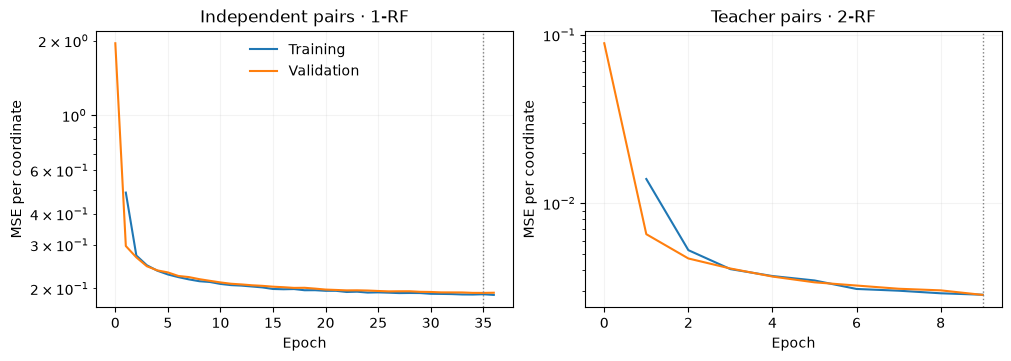

In [8]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, history, title in zip(
    axes, [teacher_history, reflow_history], ["Independent pairs · 1-RF", "Teacher pairs · 2-RF"]
):
    ax.plot(np.arange(1, len(history["train"]) + 1), history["train"], label="Training")
    ax.plot(np.arange(len(history["val"])), history["val"], label="Validation")
    ax.axvline(history["best_epoch"], color="0.5", ls=":", lw=1)
    ax.set(title=title, xlabel="Epoch", ylabel="MSE per coordinate", yscale="log")
    ax.grid(alpha=0.15)
axes[0].legend(frameon=False)
plt.show()

## Extra-training control

In [11]:
control, control_history = fit(
    teacher, train_images, (val0, val1),
    epochs=len(reflow_history["train"]), batches=pair_count // batch_size,
    stop_early=False, seed=5,
)
assert control_history["updates"] == reflow_history["updates"]

models = [teacher, control, student]
names = ["Original", "Extra training", "Reflow"]
colors = ["0.35", "#c36a30", "#247a9a"]
print(f"Extra updates per model: {reflow_history['updates']:,}")
print(f"Teacher training: {teacher_history['seconds']:.1f} s")
print(f"Teacher-pair generation: {pair_seconds:.1f} s")
print(f"Reflow training: {reflow_history['seconds']:.1f} s")
print(f"Control training: {control_history['seconds']:.1f} s")

  1 | train 0.19039 | val 0.19185


  2 | train 0.19120 | val 0.19167


  3 | train 0.18809 | val 0.19238


  4 | train 0.18971 | val 0.19359


  5 | train 0.18815 | val 0.19386


  6 | train 0.19002 | val 0.19227


  7 | train 0.18748 | val 0.19165


  8 | train 0.18823 | val 0.19237


  9 | train 0.18925 | val 0.19292
Selected epoch 7 | val 0.19165
Extra updates per model: 576
Teacher training: 312.2 s
Teacher-pair generation: 124.6 s
Reflow training: 13.5 s
Control training: 13.2 s


## Few-step generation

In [12]:
steps_grid = np.array([1, 2, 4, 8, 16, 32, 64])
evaluation_noise = jax.random.normal(jax.random.key(30), (256, 32, 32, 3))
evaluation_batch = 64

reference_images = np.stack([
    np.concatenate([
        np.asarray(heun(params, evaluation_noise[i:i + evaluation_batch], steps=128))
        for i in range(0, len(evaluation_noise), evaluation_batch)
    ]) for params in models
])
reference_fine = np.stack([
    np.asarray(heun(params, evaluation_noise[:32], steps=256)) for params in models
])
reference_floor = np.sqrt(np.mean(
    (reference_fine - reference_images[:, :32])**2, axis=(1, 2, 3, 4)
))

sample_images = np.stack([
    np.stack([
        np.concatenate([
            np.asarray(euler(params, evaluation_noise[i:i + evaluation_batch], steps=int(steps)))
            for i in range(0, len(evaluation_noise), evaluation_batch)
        ]) for steps in steps_grid
    ]) for params in models
])
assert (np.isfinite(sample_images).all() and np.isfinite(reference_images).all()
        and np.isfinite(reference_fine).all())

endpoint_rmse = np.sqrt(np.mean(
    (sample_images - reference_images[:, None])**2, axis=(-3, -2, -1)
))
teacher_drift = np.sqrt(np.mean(
    (sample_images - reference_images[0][None, None])**2, axis=(-3, -2, -1)
))
for name, error in zip(names, reference_floor):
    print(f"{name}: Heun 128-to-256 endpoint RMSE = {error:.6f}")

Original: Heun 128-to-256 endpoint RMSE = 0.000486
Extra training: Heun 128-to-256 endpoint RMSE = 0.000530
Reflow: Heun 128-to-256 endpoint RMSE = 0.000229


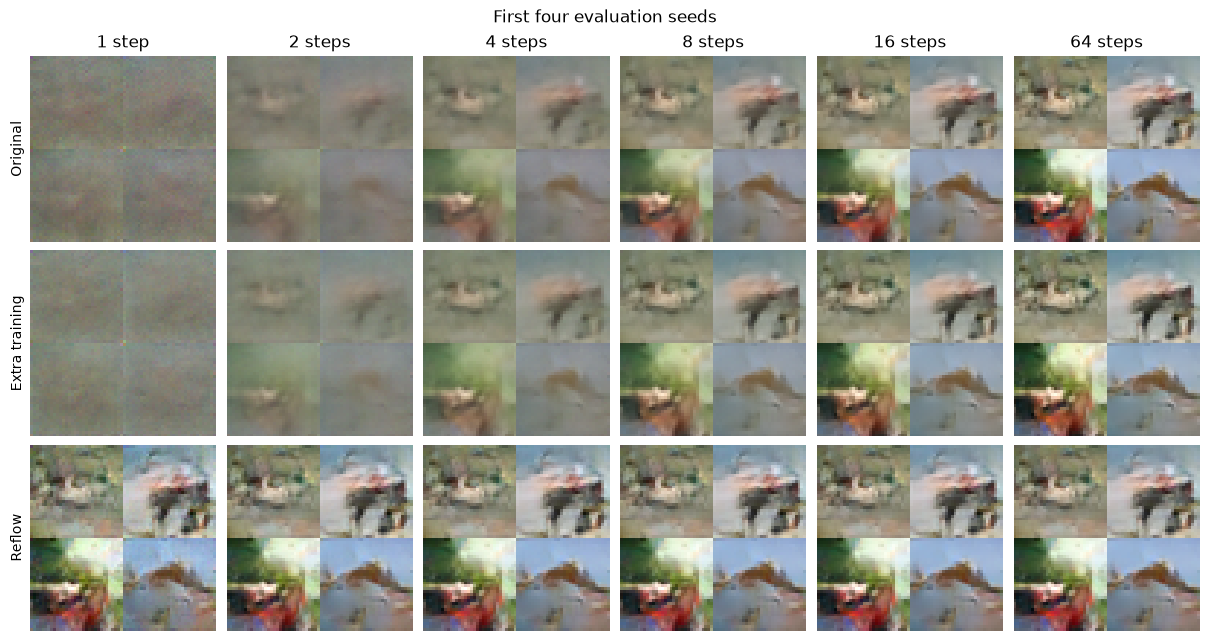

In [13]:
display_steps = [1, 2, 4, 8, 16, 64]
fig, axes = plt.subplots(3, 6, figsize=(12, 6.3), layout="constrained")
for row, name in enumerate(names):
    for col, steps in enumerate(display_steps):
        index = np.flatnonzero(steps_grid == steps)[0]
        tile = (sample_images[row, index, :4].reshape(2, 2, 32, 32, 3)
                .transpose(0, 2, 1, 3, 4).reshape(64, 64, 3))
        ax = axes[row, col]
        ax.imshow(np.clip((tile + 1) / 2, 0, 1), interpolation="nearest")
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(f"{steps} step" + ("s" if steps > 1 else ""))
        if col == 0:
            ax.set_ylabel(name)
fig.suptitle("First four evaluation seeds", fontsize=12)
plt.show()

## Numerical error and straightness

$$
e_N=\frac{\|x_N-x_{\mathrm{ref}}\|}{\sqrt d},\qquad
b(t)=\frac{\|x_t-[(1-t)x_0+tx_1]\|}{\sqrt d},\qquad d=3072.
$$

In [14]:
@partial(jax.jit, static_argnames=("steps",))
def heun_path(params, noise, steps=128):
    def advance(x, k):
        t = jnp.full((len(x), 1, 1, 1), k / steps, dtype=x.dtype)
        v0 = model_apply(params, x, t)
        proposal = x + v0 / steps
        v1 = model_apply(params, proposal, t + 1 / steps)
        next_x = x + (v0 + v1) / (2 * steps)
        return next_x, next_x

    _, states = jax.lax.scan(advance, noise, jnp.arange(steps))
    return jnp.concatenate([noise[None], states], axis=0)


paths = np.stack([
    np.asarray(heun_path(params, evaluation_noise[:32], steps=128)) for params in models
])
path_times = np.linspace(0, 1, paths.shape[1], dtype=np.float32)
weights = path_times[None, :, None, None, None, None]
chords = (1 - weights) * paths[:, :1] + weights * paths[:, -1:]
chord_deviation = np.sqrt(np.mean((paths - chords)**2, axis=(-3, -2, -1)))
assert np.isfinite(paths).all()
del chords

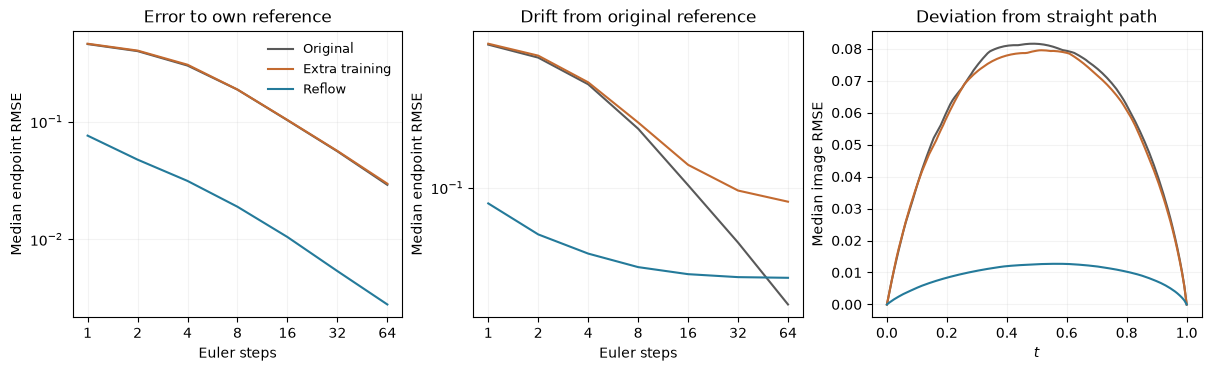

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for i, (name, color) in enumerate(zip(names, colors)):
    axes[0].loglog(steps_grid, np.median(endpoint_rmse[i], axis=1),
                   color=color, label=name)
    axes[1].loglog(steps_grid, np.median(teacher_drift[i], axis=1), color=color)
    axes[2].plot(path_times, np.median(chord_deviation[i], axis=1), color=color)
axes[0].set(title="Error to own reference", ylabel="Median endpoint RMSE")
axes[1].set(title="Drift from original reference", ylabel="Median endpoint RMSE")
axes[2].set(title="Deviation from straight path", xlabel="$t$", ylabel="Median image RMSE")
for ax in axes[:2]:
    ax.set(xlabel="Euler steps", xticks=steps_grid, xticklabels=steps_grid)
    ax.minorticks_off()
for ax in axes:
    ax.grid(alpha=0.15)
axes[0].legend(frameon=False, fontsize=9)
plt.show()

## Endpoint estimates along the path

$$\widehat x_1(t)=x_t+(1-t)v_\theta(x_t,t).$$

In [16]:
@jax.jit
def estimate_endpoint(params, states, times):
    return states + (1 - times) * model_apply(params, states, times)


estimate_indices = np.array([0, 32, 64, 96, 128])
estimate_times = jnp.asarray(path_times[estimate_indices], dtype=jnp.float32)[:, None, None, None]
endpoint_estimates = np.stack([
    np.asarray(estimate_endpoint(params, jnp.asarray(paths[i, estimate_indices, 0]), estimate_times))
    for i, params in enumerate(models)
])

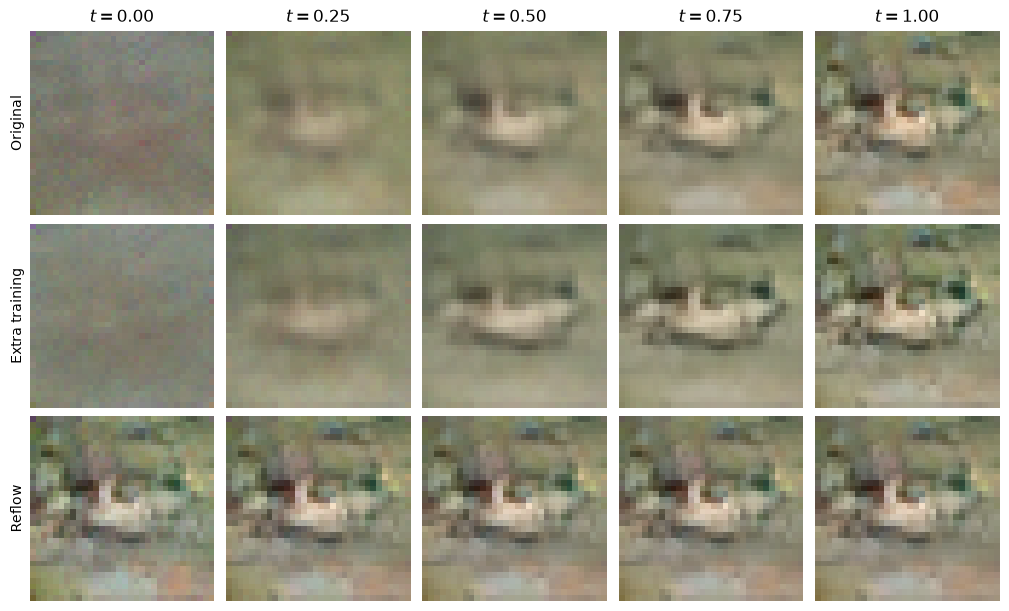

In [17]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6), layout="constrained")
for row, name in enumerate(names):
    for col, index in enumerate(estimate_indices):
        ax = axes[row, col]
        ax.imshow(np.clip((endpoint_estimates[row, col] + 1) / 2, 0, 1),
                  interpolation="nearest")
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(f"$t={path_times[index]:.2f}$")
        if col == 0:
            ax.set_ylabel(name)
plt.show()

## Pixel distribution and sampling time

$$
\widehat{\mathrm{SW}}_2^2(P,Q)
=\frac1{Ln}\sum_{\ell=1}^{L}\sum_{i=1}^{n}
\left[(a_\ell^\top x)_{(i)}-(a_\ell^\top y)_{(i)}\right]^2,
\qquad \|a_\ell\|=1.
$$

In [18]:
test_indices = np.random.default_rng(31).choice(len(data["test"]), 512, replace=False)
test_images = np.stack([
    np.asarray(image) for image in data["test"][test_indices.tolist()]["img"]
]).astype(np.float32) / 127.5 - 1
real_a, real_b = test_images[:256], test_images[256:]

directions = np.random.default_rng(32).standard_normal((3072, 256)).astype(np.float32)
directions /= np.linalg.norm(directions, axis=0, keepdims=True)
real_a_projection = np.sort(real_a.reshape(256, -1) @ directions, axis=0)
real_b_projection = np.sort(real_b.reshape(256, -1) @ directions, axis=0)
sample_projection = sample_images.reshape(-1, 3072) @ directions
sample_projection = np.sort(sample_projection.reshape(3, len(steps_grid), 256, 256), axis=2)
sliced_w2 = 0.5 * (
    np.sqrt(np.mean((sample_projection - real_a_projection[None, None])**2, axis=(2, 3)))
    + np.sqrt(np.mean((sample_projection - real_b_projection[None, None])**2, axis=(2, 3)))
)
real_reference = np.sqrt(np.mean((real_a_projection - real_b_projection)**2))

latency_ms = np.empty((3, len(steps_grid)))
for i, params in enumerate(models):
    for j, steps in enumerate(steps_grid):
        euler(params, evaluation_noise[:64], steps=int(steps)).block_until_ready()
        durations = []
        for _ in range(3):
            started = perf_counter()
            euler(params, evaluation_noise[:64], steps=int(steps)).block_until_ready()
            durations.append(perf_counter() - started)
        latency_ms[i, j] = 1000 * np.median(durations)

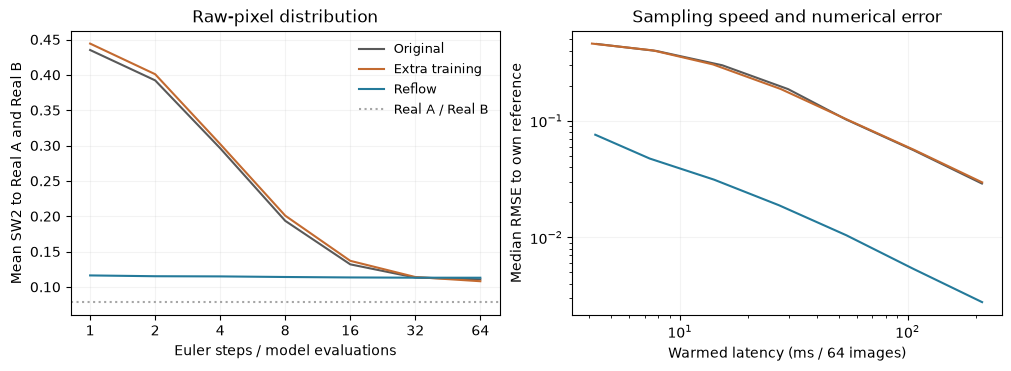

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for i, (name, color) in enumerate(zip(names, colors)):
    axes[0].plot(steps_grid, sliced_w2[i], color=color, label=name)
    axes[1].loglog(latency_ms[i], np.median(endpoint_rmse[i], axis=1), color=color)
axes[0].axhline(real_reference, color="0.65", ls=":", lw=1.5, label="Real A / Real B")
axes[0].set(title="Raw-pixel distribution", ylabel="Mean SW2 to Real A and Real B",
            xscale="log", xlabel="Euler steps / model evaluations",
            xticks=steps_grid, xticklabels=steps_grid)
axes[0].minorticks_off()
axes[1].set(title="Sampling speed and numerical error", xlabel="Warmed latency (ms / 64 images)",
            ylabel="Median RMSE to own reference")
for ax in axes:
    ax.grid(alpha=0.15)
axes[0].legend(frameon=False, fontsize=9)
plt.show()